In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sqlite3

print("Libraries imported successfully")

Libraries imported successfully


upload dataset

In [2]:
from google.colab import files

uploaded = files.upload()


Saving Sample - Superstore.csv to Sample - Superstore.csv


In [3]:
file_name = next(iter(uploaded))
df = pd.read_csv(file_name, encoding="cp1252")
print("Dataset uploaded successfully")

Dataset uploaded successfully


view the first 5 records

In [4]:
df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


check the number of rows and columns

In [5]:
print("Dataset Shape:", df.shape)

Dataset Shape: (9994, 21)


check column names

In [6]:
print(df.columns.tolist())

['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit']


understand the data types

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9994 non-null   int64  
 1   Order ID       9994 non-null   object 
 2   Order Date     9994 non-null   object 
 3   Ship Date      9994 non-null   object 
 4   Ship Mode      9994 non-null   object 
 5   Customer ID    9994 non-null   object 
 6   Customer Name  9994 non-null   object 
 7   Segment        9994 non-null   object 
 8   Country        9994 non-null   object 
 9   City           9994 non-null   object 
 10  State          9994 non-null   object 
 11  Postal Code    9994 non-null   int64  
 12  Region         9994 non-null   object 
 13  Product ID     9994 non-null   object 
 14  Category       9994 non-null   object 
 15  Sub-Category   9994 non-null   object 
 16  Product Name   9994 non-null   object 
 17  Sales          9994 non-null   float64
 18  Quantity

get statistical information

In [8]:
df.describe()

,Row ID,Postal Code,Sales,Quantity,Discount,Profit
count,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000
mean,4997.500000,55190.379428,229.858001,3.789574,0.156203,28.656896
std,2885.163629,32063.693350,623.245101,2.225110,0.206452,234.260108
min,1.000000,1040.000000,0.444000,1.000000,0.000000,-6599.978000
25%,2499.250000,23223.000000,17.280000,2.000000,0.000000,1.728750
50%,4997.500000,56430.500000,54.490000,3.000000,0.200000,8.666500
75%,7495.750000,90008.000000,209.940000,5.000000,0.200000,29.364000
max,9994.000000,99301.000000,22638.480000,14.000000,0.800000,8399.976000


**Data cleaning**

check the missing values

In [9]:
df.isnull().sum()

,0
Row ID,0
Order ID,0
Order Date,0
Ship Date,0
Ship Mode,0
Customer ID,0
Customer Name,0
Segment,0
Country,0
City,0


check duplicate records

In [10]:
print("Duplicate records:", df.duplicated().sum())

Duplicate records: 0


remove duplicate rows if any

In [11]:
df = df.drop_duplicates()

print("Duplicates removed successfully!")

Duplicates removed successfully!


clean column names

In [12]:
df.columns = (
    df.columns
    .str.strip()
    .str.lower()
    .str.replace(r"[^a-z0-9]+", "_", regex=True)
    .str.strip("_")
)

print(df.columns.tolist())

['row_id', 'order_id', 'order_date', 'ship_date', 'ship_mode', 'customer_id', 'customer_name', 'segment', 'country', 'city', 'state', 'postal_code', 'region', 'product_id', 'category', 'sub_category', 'product_name', 'sales', 'quantity', 'discount', 'profit']


convert the date columns

In [15]:

df["order_date"] = pd.to_datetime(
    df["order_date"], errors="coerce"
)
df["ship_date"] = pd.to_datetime(
    df["ship_date"], errors = "coerce"
)

verify numerical columns

In [16]:
numeric_columns = ["sales", "quantity", "discount", "profit"]
for col in numeric_columns:
  df[col] = pd.to_numeric(df[col], errors ="coerce")

df[numeric_columns].info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 4 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   sales     9994 non-null   float64
 1   quantity  9994 non-null   int64  
 2   discount  9994 non-null   float64
 3   profit    9994 non-null   float64
dtypes: float64(3), int64(1)
memory usage: 312.4 KB


verify cleaning

In [17]:
print("Rows and columns:", df.shape)

print("\nMisisng values: ")
print(df.isnull().sum())

print("\nDuplicate records: ")
print(df.duplicated().sum())

Rows and columns: (9994, 21)

Misisng values: 
row_id           0
order_id         0
order_date       0
ship_date        0
ship_mode        0
customer_id      0
customer_name    0
segment          0
country          0
city             0
state            0
postal_code      0
region           0
product_id       0
category         0
sub_category     0
product_name     0
sales            0
quantity         0
discount         0
profit           0
dtype: int64

Duplicate records: 
0


calculate key business metrics called key performance indicators (KPIs)

In [18]:
total_sales = df["sales"].sum()
total_profit = df["profit"].sum()
total_orders = df["order_id"].nunique()
total_customers = df["customer_id"].nunique()
total_quantity = df["quantity"].sum()

average_order_value = (
    df.groupby("order_id")["sales"].sum().mean()
)
print("Total Sales:", round(total_sales, 2))

print("Total Profit:", round(total_profit, 2))

print("Total Orders:", total_orders)

print("Total Customers:", total_customers)

print("Total Quantity:", total_quantity)

print("Average Order Value:", round(average_order_value, 2))


Total Sales: 2297200.86
Total Profit: 286397.02
Total Orders: 5009
Total Customers: 793
Total Quantity: 37873
Average Order Value: 458.61


Find the top 10 selling products

In [19]:
top_products = (
    df.groupby("product_name")["sales"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print(top_products)

product_name
Canon imageCLASS 2200 Advanced Copier                                          61599.824
Fellowes PB500 Electric Punch Plastic Comb Binding Machine with Manual Bind    27453.384
Cisco TelePresence System EX90 Videoconferencing Unit                          22638.480
HON 5400 Series Task Chairs for Big and Tall                                   21870.576
GBC DocuBind TL300 Electric Binding System                                     19823.479
GBC Ibimaster 500 Manual ProClick Binding System                               19024.500
Hewlett Packard LaserJet 3310 Copier                                           18839.686
HP Designjet T520 Inkjet Large Format Printer - 24" Color                      18374.895
GBC DocuBind P400 Electric Binding System                                      17965.068
High Speed Automatic Electric Letter Opener                                    17030.312
Name: sales, dtype: float64


Analyze sales by region

In [20]:
region_sales = (
    df.groupby("region")
    [["sales", "profit"]]
    .sum()
    .sort_values("sales", ascending=False)
)

print(region_sales)

               sales       profit
region                           
West     725457.8245  108418.4489
East     678781.2400   91522.7800
Central  501239.8908   39706.3625
South    391721.9050   46749.4303


Analyze product categories

In [21]:
category_analysis = (
    df.groupby("category")
    [["sales", "profit", "quantity"]]
    .sum()
)

print(category_analysis)

                       sales       profit  quantity
category                                           
Furniture        741999.7953   18451.2728      8028
Office Supplies  719047.0320  122490.8008     22906
Technology       836154.0330  145454.9481      6939


Analyze customer segments

In [22]:
segment_analysis = (
    df.groupby("segment")
    [["sales", "profit"]]
    .sum()
)

print(segment_analysis)

                    sales       profit
segment                               
Consumer     1.161401e+06  134119.2092
Corporate    7.061464e+05   91979.1340
Home Office  4.296531e+05   60298.6785


Identify loss-making subcategories

In [23]:
subcategory_profit = (
    df.groupby("sub_category")["profit"]
    .sum()
    .sort_values()
)

print(subcategory_profit)

sub_category
Tables        -17725.4811
Bookcases      -3472.5560
Supplies       -1189.0995
Fasteners        949.5182
Machines        3384.7569
Labels          5546.2540
Art             6527.7870
Envelopes       6964.1767
Furnishings    13059.1436
Appliances     18138.0054
Storage        21278.8264
Chairs         26590.1663
Binders        30221.7633
Paper          34053.5693
Accessories    41936.6357
Phones         44515.7306
Copiers        55617.8249
Name: profit, dtype: float64


In [39]:
df.to_csv(
    "cleaned_superstore_sales.csv",
    index=False
)

print("Cleaned dataset exported successfully!")

Cleaned dataset exported successfully!


In [40]:
from google.colab import files

files.download("cleaned_superstore_sales.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

**Data Visualization**

Sales By region

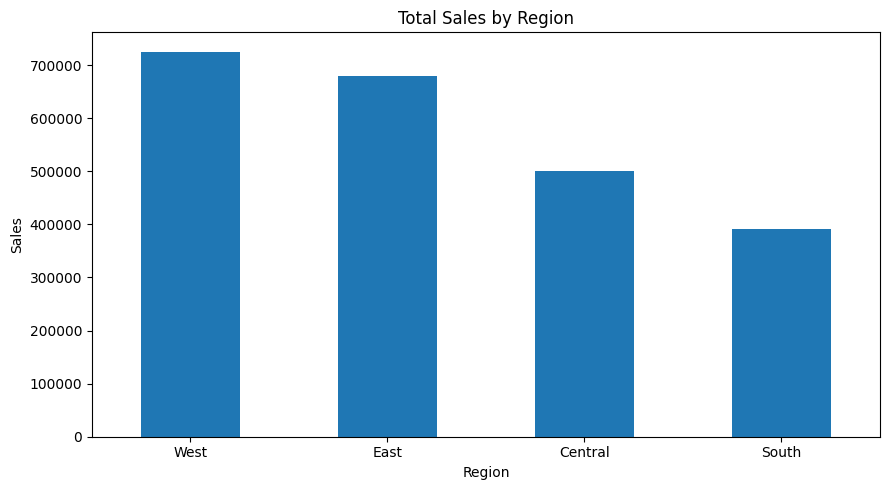

In [24]:
plt.figure(figsize=(9, 5))

region_sales["sales"].plot(kind="bar")

plt.title("Total Sales by Region")
plt.xlabel("Region")
plt.ylabel("Sales")

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Sales by category

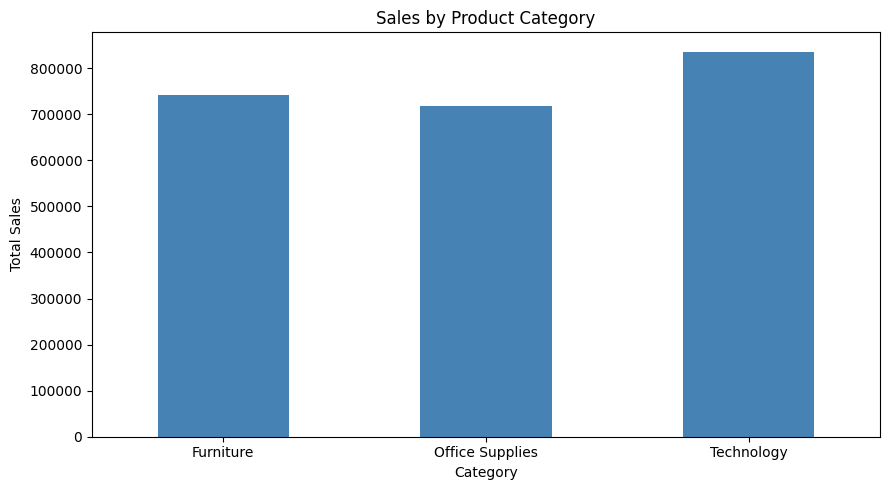

In [25]:
plt.figure(figsize=(9, 5))

category_analysis["sales"].plot(
    kind="bar",
    color="steelblue"
)

plt.title("Sales by Product Category")
plt.xlabel("Category")
plt.ylabel("Total Sales")

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Monthly sales trend

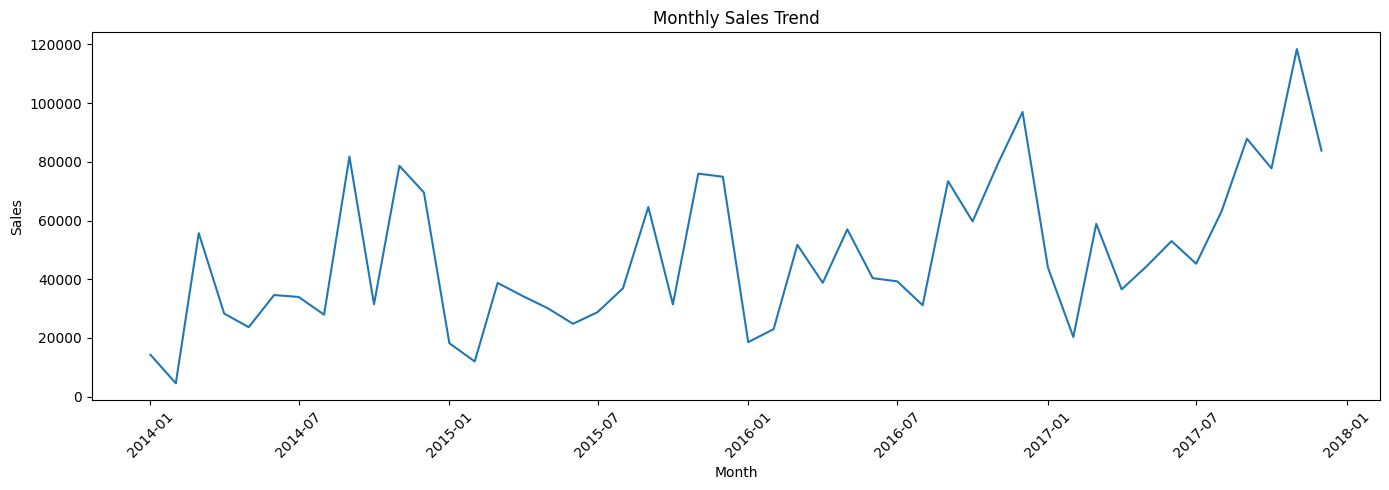

In [26]:
monthly_sales = (
    df.set_index("order_date")
    .resample("MS")["sales"]
    .sum()
)

plt.figure(figsize=(14, 5))

plt.plot(monthly_sales.index, monthly_sales.values)

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Sales")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Profit by subcategory

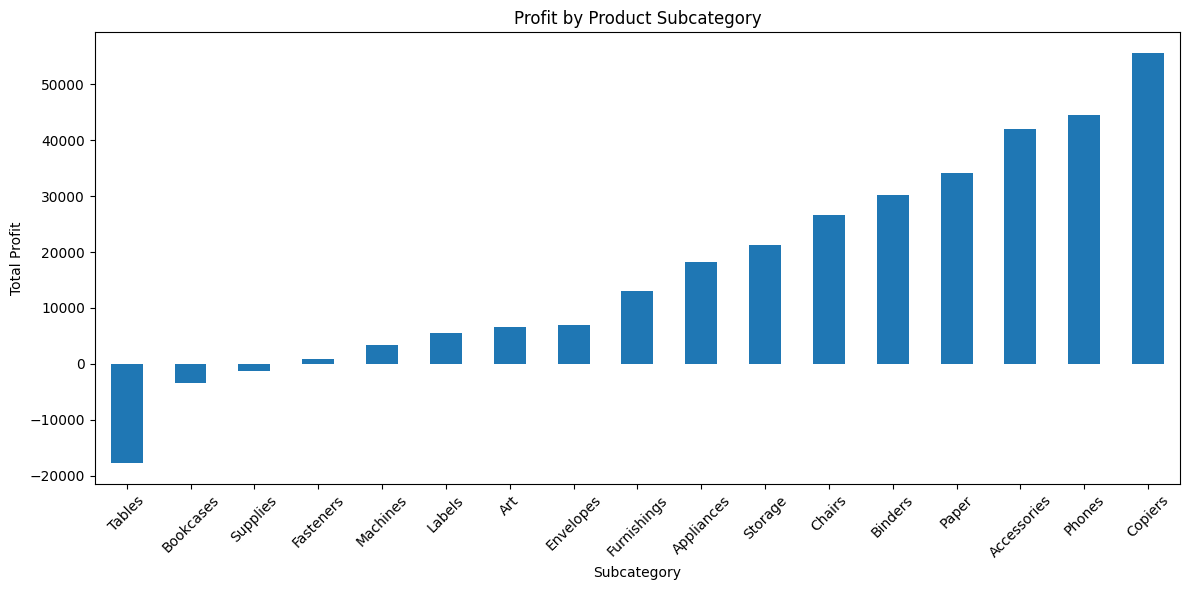

In [27]:
plt.figure(figsize=(12, 6))

subcategory_profit.sort_values().plot(kind="bar")

plt.title("Profit by Product Subcategory")
plt.xlabel("Subcategory")
plt.ylabel("Total Profit")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**SQL Analysis**

Create a SQL database

In [28]:
conn = sqlite3.connect(":memory:")
df.to_sql(
    "sales",
    conn,
    index = False,
    if_exists = "replace"
)

print("SQL database created successfully")


SQL database created successfully


Find total sales and profit

In [29]:
query = """
SELECT
   SUM(sales) AS total_sales,
   SUM(profit) AS total_profit
FROM sales;
"""

result = pd.read_sql_query(query, conn)
display(result)

,total_sales,total_profit
0,2.297201e+06,286397.0217


Find sales by region

In [30]:
query = """
SELECT
   region,
   SUM(sales) AS total_sales,
   SUM(profit) AS total_profit
FROM sales
GROUP BY region
ORDER BY total_sales DESC;
"""

region_result = pd.read_sql_query(query, conn)
display(region_result)


,region,total_sales,total_profit
0,West,725457.8245,108418.4489
1,East,678781.2400,91522.7800
2,Central,501239.8908,39706.3625
3,South,391721.9050,46749.4303


Find the top 10 products

In [31]:
query = """
SELECT
   product_name,
   SUM(sales) AS total_sales
FROM sales
GROUP BY product_name
ORDER BY total_sales DESC
LIMIT 10
"""

top_product_sql = pd.read_sql_query(query, conn)
display(top_product_sql)

,product_name,total_sales
0,Canon imageCLASS 2200 Advanced Copier,61599.824
1,Fellowes PB500 Electric Punch Plastic Comb Bin...,27453.384
2,Cisco TelePresence System EX90 Videoconferenci...,22638.480
3,HON 5400 Series Task Chairs for Big and Tall,21870.576
4,GBC DocuBind TL300 Electric Binding System,19823.479
5,GBC Ibimaster 500 Manual ProClick Binding System,19024.500
6,Hewlett Packard LaserJet 3310 Copier,18839.686
7,HP Designjet T520 Inkjet Large Format Printer ...,18374.895
8,GBC DocuBind P400 Electric Binding System,17965.068
9,High Speed Automatic Electric Letter Opener,17030.312


Find loss-making subcategories

In [32]:
query = """
SELECT
   sub_category,
   SUM(profit) AS total_profit
FROM sales
GROUP BY sub_category
HAVING SUM(profit) < 0
ORDER BY total_profit ASC;
"""

loss_result = pd.read_sql_query(query, conn)
display(loss_result)

,sub_category,total_profit
0,Tables,-17725.4811
1,Bookcases,-3472.5560
2,Supplies,-1189.0995


**Business Insights and Recommendations**

Which region generated the highest sales?

In [33]:
highest_sales_region = region_sales["sales"].idxmax() #idxmax() finds the index (region name) with the highest sales
highest_sales_value = region_sales["sales"].max() #max() finds the highest sales value

print("Highest Sales Region: ", highest_sales_region)
print("Total Sales: ", round(highest_sales_value, 2))

Highest Sales Region:  West
Total Sales:  725457.82


Which category generated the highest profit?

In [34]:
highest_profit_category = category_analysis["profit"].idxmax()

highest_profit_value = category_analysis["profit"].max()

print("Most Profitable Category:", highest_profit_category)
print("Total Profit:", round(highest_profit_value, 2))

Most Profitable Category: Technology
Total Profit: 145454.95


Which subcategories generated losses?

In [35]:
loss_making = subcategory_profit[subcategory_profit < 0]
print(loss_making)

sub_category
Tables      -17725.4811
Bookcases    -3472.5560
Supplies     -1189.0995
Name: profit, dtype: float64


Which products genrated the highest revenue?

In [36]:
print(top_products.head(5))

product_name
Canon imageCLASS 2200 Advanced Copier                                          61599.824
Fellowes PB500 Electric Punch Plastic Comb Binding Machine with Manual Bind    27453.384
Cisco TelePresence System EX90 Videoconferencing Unit                          22638.480
HON 5400 Series Task Chairs for Big and Tall                                   21870.576
GBC DocuBind TL300 Electric Binding System                                     19823.479
Name: sales, dtype: float64


Which customer segment generated the highest sales?

In [37]:
segment_sales = df.groupby("segment")["sales"].sum()

print(segment_sales.sort_values(ascending=False))

segment
Consumer       1.161401e+06
Corporate      7.061464e+05
Home Office    4.296531e+05
Name: sales, dtype: float64


Which month generated the highest sales?

In [38]:
best_month = monthly_sales.idxmax()

best_month_sales = monthly_sales.max()

print("Best Sales Month:", best_month)
print("Sales:", round(best_month_sales, 2))

Best Sales Month: 2017-11-01 00:00:00
Sales: 118447.82


**Key Business Insights**

1. Regional Performance:
The region with the highest total sales was West.

2. Category Performance:
The technology category generated the hoghest total profit.

3. Loss-making Product:
Th efollowing subcategories generated negative profit: tables, books and supplies

4. Product Performance:
The top five products contributed significant sales revenue.

5. Customer Segmentation:
The cooperate segment generated the highest sales.

6. Monthly Performance:
The highest sales were recorded in
November 2017-11-01.

**Business Insights and Recommendations**

**Insight 1: Regional Sales Performance**

In [ ]:
df.groupby("region")["sales"].sum().sort_values(ascending=False)

,sales
region,
West,725457.8245
East,678781.2400
Central,501239.8908
South,391721.9050


Finding: The West region generated the highest sales (725,457.82), followed by East (678,781.24).



Interpretation: The West region is the strongest contributor to total sales.



Recommendation: The business should maintain product availability in the West region and investigate successful sales strategies that could be applied to other regions.

**Insight 2: Product Profitability**

In [ ]:
df.groupby("sub_category")["profit"].sum().sort_values()

,profit
sub_category,
Tables,-17725.4811
Bookcases,-3472.5560
Supplies,-1189.0995
Fasteners,949.5182
Machines,3384.7569
Labels,5546.2540
Art,6527.7870
Envelopes,6964.1767
Furnishings,13059.1436


Finding: Tables recorded the highest negative profit (-17,725.48), followed by Bookcases (-3,472.56) and Supplies (-1,189.10).



Interpretation: These three sub-categories generated losses during the analysed period.



Recommendation: The business should review pricing, discount levels and product costs for these sub-categories to identify opportunities to reduce losses.

**Insight 3: Monthly Sales Trends**

In [ ]:
df.groupby(df["order_date"].dt.month)["sales"].sum()

,sales
order_date,
1,94924.8356
2,59751.2514
3,205005.4888
4,137762.1286
5,155028.8117
6,152718.6793
7,147238.0970
8,159044.0630
9,307649.9457


Finding: November recorded the highest total sales (352,461.07), followed by December (325,293.50) and September (307,649.95).



Interpretation: Sales were higher during these months across the dataset.



Recommendation: The business should consider preparing inventory and promotional campaigns ahead of these high-sales months to meet customer demand.

This analysis provides insights into regional performance, product profitability, discount patterns and monthly sales trends. These findings can support better business decisions related to pricing, inventory and sales strategies.

**Conclusion**

This project involved analysing retail sales data using Python, Pandas and SQL. The analysis explored regional sales performance, product profitability, discount patterns and monthly sales trends.

The findings highlighted differences in regional performance and identified product categories that generated losses. Data visualizations and SQL queries were also used to explore the dataset and summarize important results.

Overall, this project helped develop practical skills in data cleaning, exploratory data analysis, data visualization, SQL querying and extracting meaningful business insights.